### Importing needed materials

In [21]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
from scipy import stats

In [22]:
data = "kine2000_music_endurance_dataset.csv"
df = pd.read_csv(data)

# deleted empty/extra columns
df = df.drop(columns=[col for col in df.columns if "Unnamed" in col])

df.head()

,Participant (anonymous ID),Lab Section (Ex: Wed 2pm),Age (years),Height (m),Weight (kg),Silence Time to Failure (s),Music Time to Failure (s),Music Genre Selected
0,1,Thursday 10am,18,1.67,62.6,125.00,136.00,Pop
1,2,Thursday 10am,20,1.83,89.4,81.81,105.99,R&B
2,3,Thursday 10am,21,1.83,96.2,70.00,91.25,Alt. Metal
3,4,Thursday 10am,18,1.79,59.6,105.00,113.00,Pop
4,5,Thursday 10am,20,1.88,96.6,77.00,93.00,Pop


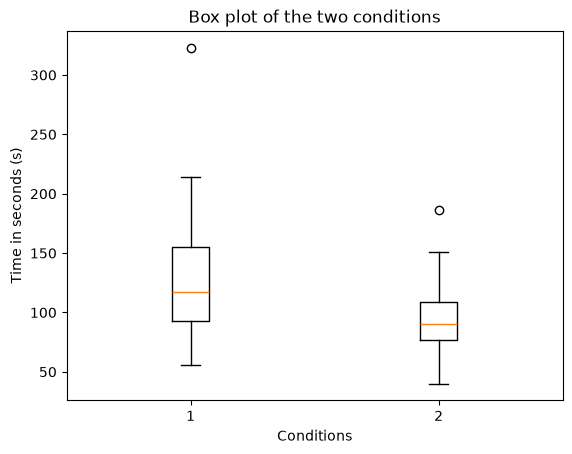

In [ ]:
fig, ax = plt.subplots()
ax.boxplot(condition_box, tick_labels=condition_box.columns)
ax.set_title("Box plot of the two conditions")
ax.set_ylabel("Time in seconds (s)")
plt.show()


In [ ]:
# Separate the groups
group_a = df[df['group'] == 'A']['value']
group_b = df[df['group'] == 'B']['value']

# Perform independent t-test
# equal_var=False is safer if variances differ (Welch's t-test)
t_stat, p_value = stats.ttest_ind(group_a, group_b, equal_var=False)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

# Interpretation
alpha = 0.05
if p_value < alpha:
    print("Reject null hypothesis: Means are significantly different.")
else:
    print("Fail to reject null hypothesis: No significant difference.")
